# Lecture 3: Sticky Prices, the Output Gap and Monetary Policy

**Lecture 3 of 9** · [Series index](README.md)

*This lecture builds on [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb) and [Lecture 2: Cass-Koopmans with Capital and Labour Adjustment Costs](02_adjustment_costs.ipynb), which adapt [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). It is shared under the same licence. The Newton solver used throughout is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0.*

## Overview

[Lecture 2](02_adjustment_costs.ipynb) built a growth model with capital and labour adjustment costs and elastic labour supply, and solved it as a CGE-style price system. Every price was flexible, so money played no role: we fixed the interest rate and let the goods price absorb all intertemporal price movement.

This lecture makes prices **sticky**, which gives monetary policy real effects. We add, in turn:

1. **Monopolistic competition.** Firms sell differentiated varieties and set their own prices. A production subsidy removes the markup from the steady state, so the flexible-price economy is exactly the one from [Lecture 2](02_adjustment_costs.ipynb).
2. **Price-adjustment costs** in the Rotemberg form, with the same quadratic shape as the capital and labour adjustment costs. The condition "price equals marginal cost" becomes a **Phillips curve**.
3. **A nominal anchor.** The nominal interest rate becomes an unknown, set by an inflation-targeting rule anchored on the flexible economy's **natural rate**.
4. **Potential output and the output gap**, defined relative to the efficient level of output for the current capital stock, and a policy rule that responds to the gap.
5. **A cost-push shock** to firms' desired markups, which separates the natural allocation from the efficient one and creates a trade-off between stabilising inflation and closing the output gap.

Throughout, the flexible-price economy of [Lecture 2](02_adjustment_costs.ipynb) serves as the **benchmark**. Each sticky-price computation is checked against it, and its real interest rate path is the natural rate the policy rule is anchored on.

The solution method is unchanged: stack every equilibrium condition for $t = 0, \ldots, T$ into one system and solve it with damped-then-full Newton steps, with JAX supplying the Jacobian.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

## Building blocks from Lecture 2

The code in this section is the flexible-price model of [Lecture 2](02_adjustment_costs.ipynb), which derives and explains it in full. We collect it here so that this lecture runs on its own.

Because the sticky-price model reuses some of these names for its own versions, the flexible model's functions are prefixed `lab_` (for the labour model), and its solver is called `run_flexible`.

### Newton's method and adjustment costs

The `newton` routine is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html).

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x


# ----- capital adjustment cost;  k = (k_0..k_{T+1}),  output indexed t = 0..T -----
def adjustment_cost(k, s):
    # AC_t = zeta k_t/2 (k_{t+1}/k_t - 1)^2, paid in goods
    return s.zeta * k[:-1] / 2 * (k[1:] / k[:-1] - 1) ** 2


# ----- labour adjustment costs;  n_ext = (n_{-1}, n_0..n_T),  outputs indexed t = 0..T -----
def labour_adj_cost(n_ext, s):
    return s.zeta_n * n_ext[1:] / 2 * (n_ext[1:] / n_ext[:-1] - 1) ** 2


def labour_adj_cost_prime_t(n_ext, s):
    # dLAC_t / dn_t
    g = n_ext[1:] / n_ext[:-1]
    return s.zeta_n / 2 * (g - 1) ** 2 + s.zeta_n * g * (g - 1)


def labour_adj_cost_prime_t1(n_ext, s):
    # dLAC_t / dn_{t-1}
    g = n_ext[1:] / n_ext[:-1]
    return -s.zeta_n * (g - 1) * g ** 2


def lead(z):
    # z_{t+1}, with z_{T+1} = 0 (no labour adjustment after T)
    return jnp.concatenate([z[1:], jnp.zeros(1)])

### The flexible-price economy

Parameters, steady-state calibration and the CGE-style price system with the interest rate fixed at $1/\beta - 1$ and $p_{y,0} = 1$.

In [3]:
LabSettings = namedtuple('LabSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'zeta',
                                         'zeta_n', 'H', 'a', 'n0', 'k_ss', 'n_ss', 'c_ss'])


def get_lab_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                     zeta=5.0, zeta_n=2.0, H=1.0, n_target=1 / 3):
    # Steady state has employment n_ss = n_target * H; the consumption weight a is calibrated to deliver it.
    kappa = ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))      # k/n in steady state
    y_n = A * kappa ** alpha
    c_n = y_n - delta * kappa
    w_ss = (1 - alpha) * y_n
    n_ss = n_target * H
    a = 1 / (1 + (H - n_ss) / n_ss * w_ss / c_n)
    k_ss, c_ss = kappa * n_ss, c_n * n_ss
    return LabSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, zeta, zeta_n, H, a, n_ss, k_ss, n_ss, c_ss)


def lab_MLAC(n_ext, p_y, s, r):
    p_next = jnp.concatenate([p_y[1:], p_y[-1:]])
    return (p_y * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + r))


def lab_unpack(x, s):
    T, n = s.T, s.T + 1
    p_y = jnp.concatenate([jnp.ones(1), jnp.exp(x[:T])])
    w, u, y, nl = (jnp.exp(x[T + i * n:T + (i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 4 * n:]), jnp.array([s.k_ss])])
    return p_y, w, u, y, nl, k


def lab_price_block(p_y, w, u, y, nl, k, s, r):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = lab_MLAC(n_ext, p_y, s, r)
    y_bt = y + ac + lac
    p_n = w + mlac
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)
    p_ks = p_y_bt * s.alpha * y_bt / ks
    p_c = p_i = p_y
    p_l = w
    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p_y * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, p_c=p_c, p_i=p_i,
                p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=s.H - leisure, I=invest, q=q)


def lab_transition_economy(x, s, solving=1):
    p_y, w, u, y, nl, k = lab_unpack(x, s)
    r = 1 / s.beta - 1
    P = lab_price_block(p_y, w, u, y, nl, k, s, r)
    price_error = (p_y - P['p_y_bt']) / p_y
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] - y) / y
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - (1 / s.gamma) * jnp.log(s.beta * (1 + r) * P['p_u'][:-1] / P['p_u'][1:]))
    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p_y[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    errors = jnp.concatenate([price_error, production_error, labour_error, goods_error,
                              household_error, r_implied - r])
    if solving:
        return errors
    econ = dict(P, p_y=p_y, w=w, u=u, y=y, n=nl, k=k, r=r,
                real_w=w / P['p_c'], r_real=(1 + r) * p_y[:-1] / p_y[1:] - 1)
    return errors, econ


def lab_initial_guess(s):
    n = s.T + 1
    kappa = s.k_ss / s.n_ss
    y_ss = s.A * kappa ** s.alpha * s.n_ss
    w_ss = (1 - s.alpha) * y_ss / s.n_ss
    u_ss = s.c_ss ** s.a * (s.H - s.n_ss) ** (1 - s.a)
    k_path = np.linspace(s.k0, s.k_ss, s.T + 2)[1:-1]
    return np.log(np.hstack((np.ones(s.T), w_ss * np.ones(n), u_ss * np.ones(n), y_ss * np.ones(n),
                             s.n_ss * np.ones(n), k_path)))


def run_flexible(**kwargs):
    s = get_lab_settings(**kwargs)
    f = lambda x: lab_transition_economy(x, s, 1)
    x1 = newton(f, lab_initial_guess(s), tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = lab_transition_economy(x, s, 0)
    return s, {k_: np.asarray(v) for k_, v in econ.items()}

# Part I: Sticky prices

## Monopolistic competition

Firms now sell differentiated varieties. A firm charging $p_{j,t}$ when the aggregate price level is $p_t$ faces demand

$$
y_{j,t} = \left(\frac{p_{j,t}}{p_t}\right)^{-\varepsilon} y_t
$$

where $\varepsilon > 1$ is the elasticity of substitution between varieties. With flexible prices each firm would set a markup $\varepsilon/(\varepsilon - 1)$ over marginal cost, which would depress output and employment below their efficient levels.

To isolate the effect of price stickiness from the effect of market power, the government pays firms a **revenue subsidy** at rate

$$
\tau_s = \frac{1}{\varepsilon - 1}
$$

financed by a lump-sum tax on the household. Then $(1 + \tau_s)(\varepsilon - 1)/\varepsilon = 1$: with flexible prices the firm sets price equal to marginal cost. The steady state and the whole flexible-price transition are exactly those of Lecture 2.

## Price-adjustment costs

Changing prices is costly. In the same quadratic form as the capital and labour adjustment costs, the **Rotemberg** price-adjustment cost, paid in final goods, is

$$
PAC_t = \frac{\zeta_p}{2} \left(\pi_t - 1\right)^2 y_t, \qquad \pi_t = \frac{p_t}{p_{t-1}}
$$

with $p_{-1} = 1$. The goods market now clears as

$$
c_t + I_t + PAC_t = y_t
$$

## The Phillips curve

Let $mc_t = p^{bt}_{y,t} / p_t$ be **real marginal cost**: nominal marginal cost relative to the price level. Each firm chooses its price path to maximise the present value of profits, discounting at the nominal rate. In a symmetric equilibrium the first-order condition is

$$
(1+\tau_s)(1-\varepsilon) + \varepsilon\, mc_t - \zeta_p (\pi_t - 1)\pi_t
+ \zeta_p (\pi_{t+1} - 1)\, \pi_{t+1}^2\, \frac{y_{t+1}/y_t}{1 + i_t} = 0
$$
(might be good to fist have the problem first then the solution)

This replaces the CGE condition $p_{y,t} = p^{bt}_{y,t}$. With $\zeta_p = 0$ it collapses to $mc_t = 1$, which is that condition. With $\zeta_p > 0$, firms pass changes in marginal cost into prices only gradually.

Linearising around zero inflation, with $\hat\pi_t = \pi_t - 1$ and $\widehat{mc}_t = mc_t - 1$, and using $(1+\tau_s)(1-\varepsilon) = -\varepsilon$, gives the familiar **New Keynesian Phillips curve**

$$
\hat\pi_t \approx \frac{\varepsilon}{\zeta_p}\, \widehat{mc}_t + \beta\, \hat\pi_{t+1}
$$
(might want some more math here)

Inflation rises when real marginal cost is above one, meaning firms would like to raise their prices but adjust them only gradually. With $\varepsilon = 6$ and $\zeta_p = 50$, the slope is $0.12$.

## A nominal anchor

In Lecture 2 the interest rate was fixed and the goods price moved freely, because nothing pinned down the level of nominal prices. Now prices have a history ($p_{t-1}$ enters the price-adjustment cost), so the price level matters and needs an anchor.

The **nominal interest rate** $i_t$ becomes an unknown, set by an inflation-targeting rule:

$$
1 + i_t = (1 + r^n_t)\, \pi_t^{\phi_\pi} \exp(\nu_t)
$$

Here $r^n_t$ is the **natural rate**: the real interest rate path of the flexible-price economy, $r^n_t = (1+r)\, p_{y,t}/p_{y,t+1} - 1$ from Lecture 2. $\nu_t$ is a **monetary policy shock**, and $\phi_\pi > 1$ satisfies the Taylor principle: the nominal rate rises more than one-for-one with inflation.

With $\nu_t = 0$, zero inflation is a solution. At $\pi_t = 1$ the Phillips curve gives $mc_t = 1$, so firms price at marginal cost; the nominal rate equals the natural rate; and the sticky economy reproduces the flexible one exactly.

## Other changes

Everything else is as in Lecture 2, except that the fixed rate $r$ is replaced by the time-varying nominal rate $i_t$ wherever the model discounts:

- the household's Euler equation, $u_{t+1}/u_t = \left(\beta (1 + i_t)\, p_{u,t}/p_{u,t+1}\right)^{1/\gamma}$,
- the firm's marginal labour adjustment cost, $MLAC_t = p_t \frac{\partial LAC_t}{\partial n_t} + \frac{p_{t+1}}{1 + i_t} \frac{\partial LAC_{t+1}}{\partial n_t}$, and
- the capital no-arbitrage condition, where the return on installed capital must now equal $i_t$.

We impose the terminal condition $\pi_T = 1$: once the economy has converged, prices are flat.

In [4]:
StickySettings = namedtuple('StickySettings', list(LabSettings._fields) + ['eps', 'tau_s', 'zeta_p', 'phi_pi'])


def get_sticky_settings(eps=6.0, zeta_p=50.0, phi_pi=1.5, **kwargs):
    # kwargs go to the labour model's settings (T, k0_frac, zeta, zeta_n, ...)
    s0 = get_lab_settings(**kwargs)
    return StickySettings(*s0, eps, 1 / (eps - 1), zeta_p, phi_pi)


def MLAC_nominal(n_ext, p, i_ext, s):
    # p_t dLAC_t/dn_t + p_{t+1}/(1+i_t) dLAC_{t+1}/dn_t  -- MLAC with a time-varying nominal rate
    p_next = jnp.concatenate([p[1:], p[-1:]])
    return (p * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + i_ext))

### The price block

As before, a price block computes every derived price and demand from the unknowns. The new entries are inflation $\pi_t$, the price-adjustment cost $PAC_t$ and real marginal cost $mc_t$. Because prices are no longer the numeraire, $p_t$ is the **price level**, and the wage $w_t$ is nominal.

In [5]:
def price_block(p, i_ext, w, u, y, nl, k, s):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = MLAC_nominal(n_ext, p, i_ext, s)

    p_prev = jnp.concatenate([jnp.ones(1), p[:-1]])
    pi = p / p_prev                                                   # inflation, p_{-1} = 1
    pac = s.zeta_p / 2 * (pi - 1) ** 2 * y                            # price adjustment cost (final goods)

    y_bt = y + ac + lac                                               # output produced
    p_n = w + mlac                                                    # price of labour input
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)                        # nominal marginal cost
    p_ks = p_y_bt * s.alpha * y_bt / ks                               # capital services price
    mc = p_y_bt / p                                                   # real marginal cost
    p_c, p_i, p_l = p, p, w

    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    N_supply = s.H - leisure

    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, pac=pac, pi=pi, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, mc=mc,
                p_c=p_c, p_i=p_i, p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=N_supply, I=invest, q=q)

### The stacked system

| Block | Equation | Periods | Count |
|---|---|---|---|
| Phillips curve | firm's pricing condition above | $0..T$ | $T+1$ |
| Production | $\log Y_t = \log(A k_t^\alpha n_t^{1-\alpha})$, with $Y_t = y_t + AC_t + LAC_t$ | $0..T$ | $T+1$ |
| Labour market | $N^s_t = n_t$ | $0..T$ | $T+1$ |
| Goods market | $c_t + I_t + PAC_t = y_t$ | $0..T$ | $T+1$ |
| Household Euler | on the utility index $u_t$, discounting at $i_t$ | $0..T-1$ | $T$ |
| Capital (no arbitrage) | return on installed capital $= i_t$ | $0..T-1$ | $T$ |
| Policy rule | $\log(1+i_t) = \log(1 + r^n_t) + \phi_\pi \log\pi_t + \nu_t$ | $0..T-1$ | $T$ |
| Terminal | $\log \pi_T = 0$ | $T$ | $1$ |

That is $7T + 5$ equations. The unknowns, all in logs, are the price level $p_0, \ldots, p_T$, gross nominal rates $1+i_0, \ldots, 1+i_{T-1}$, and $w_t, u_t, y_t, n_t$ for $t = 0, \ldots, T$, plus $k_1, \ldots, k_T$: also $7T + 5$.

The household budget is again implied by Walras' law. Firm dividends can be computed two ways: directly, as subsidised revenue less wages, investment and price-adjustment costs; or through factor payments, as in Lecture 2, plus the markup over marginal cost. We report the household budget and the gap between the two dividend measures as checks.

In [6]:
def sticky_unpack(x, s):
    T, n = s.T, s.T + 1
    p = jnp.exp(x[:n])
    ri = jnp.exp(x[n:n + T])                                          # 1 + i_t, t = 0..T-1
    w, u, y, nl = (jnp.exp(x[n + T + j * n:n + T + (j + 1) * n]) for j in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[n + T + 4 * n:]), jnp.array([s.k_ss])])   # k_0..k_{T+1}
    return p, ri, w, u, y, nl, k


def sticky_transition_economy(x, s, rn, nu, solving=1):
    p, ri, w, u, y, nl, k = sticky_unpack(x, s)
    T = s.T
    i = ri - 1
    i_ext = jnp.concatenate([i, i[-1:]])                              # i_T is never used (its coefficient is 0)
    P = price_block(p, i_ext, w, u, y, nl, k, s)
    pi = P['pi']
    pi_next = jnp.concatenate([pi[1:], jnp.ones(1)])                  # pi_{T+1} = 1
    y_next = jnp.concatenate([y[1:], y[-1:]])

    phillips_error = ((1 + s.tau_s) * (1 - s.eps) + s.eps * P['mc'] - s.zeta_p * (pi - 1) * pi
                      + s.zeta_p * (pi_next - 1) * pi_next ** 2 * (y_next / y) / (1 + i_ext))
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] + P['pac'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * ri * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - i

    rule_error = jnp.log(ri) - (jnp.log(1 + rn) + s.phi_pi * jnp.log(pi[:T]) + nu[:T])
    terminal_error = jnp.log(pi[T:])

    errors = jnp.concatenate([phillips_error, production_error, labour_error, goods_error, household_error,
                              capital_error, rule_error, terminal_error])
    if solving:
        return errors

    div = (1 + s.tau_s) * p * y - w * nl - P['p_i'] * P['I'] - p * P['pac']          # dividends, direct
    div_factor = (P['p_ks'] * k[:-1] + P['mlac'] * nl - P['p_y_bt'] * (P['ac'] + P['lac'])
                  - P['p_i'] * P['I'] - p * P['pac'] + ((1 + s.tau_s) * p - P['p_y_bt']) * y)   # via factor payments
    tax = s.tau_s * p * y                                                            # lump-sum tax funds subsidy
    budget = P['p_c'] * P['c'] - (w * nl + div_factor - tax)                         # Walras check
    econ = dict(P, p=p, i=i, w=w, u=u, y=y, n=nl, k=k, div=div, budget=budget, div_gap=div - div_factor,
                real_w=w / p, r_real=ri[:T] / pi[1:] - 1, nu=nu)
    return errors, econ

### The flexible economy as benchmark and starting point

The flexible-price economy plays two roles. Its real interest rate path is the natural rate $r^n_t$ in the policy rule. And its allocation, with zero inflation and $i_t = r^n_t$, is the initial guess for Newton. Because zero inflation solves the sticky model when there is no shock, that guess is then already the solution.

In [7]:
def benchmark(**kwargs):
    # Flexible-price economy (the labour model). Its real interest rate path is the natural rate r^n_t.
    s_lab, econ_b = run_flexible(**kwargs)
    return econ_b


def guess_from_benchmark(s, econ_b):
    # Zero inflation (p = 1), i_t = r^n_t, real allocation = benchmark; w is then the real wage.
    T = s.T
    return np.log(np.hstack((np.ones(T + 1), 1 + econ_b['r_real'], econ_b['real_w'], econ_b['u'], econ_b['y'],
                             econ_b['n'], econ_b['k'][1:T + 1])))


def run_sticky(econ_b, nu=None, damp=0.3, verbose=True, **kwargs):
    s = get_sticky_settings(**kwargs)
    nu = jnp.zeros(s.T + 1) if nu is None else jnp.asarray(nu)
    rn = jnp.asarray(econ_b['r_real'])
    f = lambda x: sticky_transition_economy(x, s, rn, nu, 1)
    x0 = guess_from_benchmark(s, econ_b)
    if verbose:
        print(f'residual at the flexible-price guess = {float(jnp.max(jnp.abs(f(x0)))):.2e}')
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=damp)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = sticky_transition_economy(x, s, rn, nu, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    if verbose:
        print(f'max |error block| = {float(jnp.max(jnp.abs(errors))):.2e}   '
              f'max |Walras budget| = {np.max(np.abs(econ["budget"])):.2e}   '
              f'max |dividend identity| = {np.max(np.abs(econ["div_gap"])):.2e}')
    return s, econ


def compare(econ, econ_b, label):
    print(f'--- {label} vs flexible benchmark ---')
    for key in ('c', 'n', 'y', 'k'):
        m = min(len(econ[key]), len(econ_b[key]))
        print(f'max |{key} diff| / benchmark = {np.max(np.abs(econ[key][:m] / econ_b[key][:m] - 1)):.2e}')
    print(f'max |pi - 1| = {np.max(np.abs(econ["pi"] - 1)):.2e}')

## Check: sticky prices change nothing without a shock

We solve the baseline transition of Lecture 2 — $k_0 = 0.3\, k_{ss}$, $T = 200$, $\zeta = 5$, $\zeta_n = 2$ — with sticky prices and no monetary shock.

In [8]:
kw = dict(zeta=5.0, zeta_n=2.0)

econ_b = benchmark(**kw)
s, econ = run_sticky(econ_b, **kw)
print(f'{7 * s.T + 5} unknowns\n')
compare(econ, econ_b, 'sticky, no shock, baseline transition')

residual at the flexible-price guess = 8.88e-15


max |error block| = 3.57e-14   max |Walras budget| = 1.44e-15   max |dividend identity| = 2.78e-16
1405 unknowns

--- sticky, no shock, baseline transition vs flexible benchmark ---
max |c diff| / benchmark = 1.11e-15
max |n diff| / benchmark = 1.11e-15
max |y diff| / benchmark = 1.33e-15
max |k diff| / benchmark = 2.22e-15
max |pi - 1| = 5.55e-16


The flexible-price guess already satisfies every equation to machine precision, so Newton has nothing to do. Inflation is zero throughout, and the sticky economy follows the flexible transition exactly.

Two things make this work. The production subsidy removes the steady-state markup, so pricing at marginal cost is what firms would choose without adjustment costs. And the policy rule is anchored on the natural rate, so it delivers exactly the real interest rates the flexible economy needs. Price stickiness only matters when something pushes the economy away from that path.

## A monetary policy shock

Now start the economy at its steady state ($k_0 = k_{ss}$, $T = 100$) and hit it with an expansionary policy shock: the rule's intercept falls by 100 basis points and the shock decays at rate $0.7$,

$$
\nu_t = -0.01 \times 0.7^t
$$

We solve it twice: with sticky prices ($\zeta_p = 50$) and with flexible prices ($\zeta_p = 0$).

In [9]:
kw_ss = dict(k0_frac=1.0, T=100, **kw)
econ_b_ss = benchmark(**kw_ss)
nu = -0.01 * 0.7 ** np.arange(kw_ss['T'] + 1)

s_st, econ_st = run_sticky(econ_b_ss, nu=nu, **kw_ss)
s_fl, econ_fl = run_sticky(econ_b_ss, nu=nu, zeta_p=0.0, **kw_ss)

print('\nflexible prices: max |real variable change| from the shock:')
for key in ('c', 'n', 'y'):
    print(f'  {key}: {np.max(np.abs(econ_fl[key] / econ_b_ss[key][:len(econ_fl[key])] - 1)):.2e}')

residual at the flexible-price guess = 1.00e-02


max |error block| = 3.75e-14   max |Walras budget| = 1.22e-15   max |dividend identity| = 2.22e-16
residual at the flexible-price guess = 1.00e-02


max |error block| = 8.88e-15   max |Walras budget| = 1.11e-15   max |dividend identity| = 2.22e-16

flexible prices: max |real variable change| from the shock:
  c: 1.11e-15
  n: 5.55e-16
  y: 8.88e-16


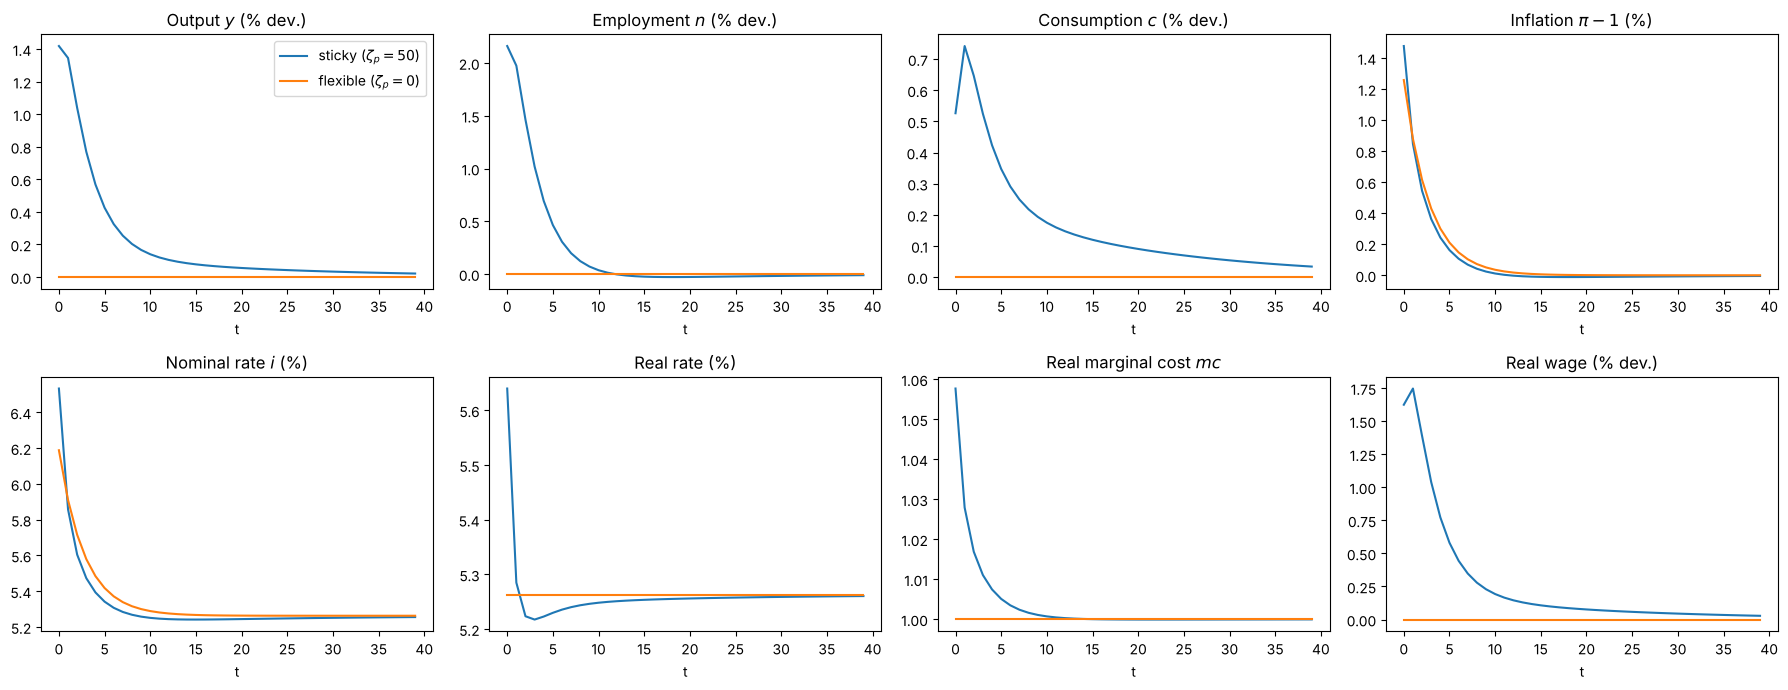

In [10]:
def plot_irf(econs, labels, t_max=40):
    fig, ax = plt.subplots(2, 4, figsize=(18, 7))
    series = [('Output $y$ (% dev.)', lambda e: 100 * (e['y'] / e['y'][-1] - 1)),
              ('Employment $n$ (% dev.)', lambda e: 100 * (e['n'] / e['n'][-1] - 1)),
              ('Consumption $c$ (% dev.)', lambda e: 100 * (e['c'] / e['c'][-1] - 1)),
              (r'Inflation $\pi - 1$ (%)', lambda e: 100 * (e['pi'] - 1)),
              ('Nominal rate $i$ (%)', lambda e: 100 * e['i']),
              ('Real rate (%)', lambda e: 100 * e['r_real']),
              ('Real marginal cost $mc$', lambda e: e['mc']),
              ('Real wage (% dev.)', lambda e: 100 * (e['real_w'] / e['real_w'][-1] - 1))]
    for a_, (title, fn) in zip(ax.flat, series):
        for e, lab in zip(econs, labels):
            a_.plot(fn(e)[:t_max], label=lab)
        a_.set_title(title)
        a_.set_xlabel('t')
    ax.flat[0].legend()
    plt.tight_layout()
    plt.show()


plot_irf([econ_st, econ_fl], [rf'sticky ($\zeta_p = {s_st.zeta_p:g}$)', r'flexible ($\zeta_p = 0$)'])

**With flexible prices, money is neutral.** The shock changes the path of the price level and the nominal interest rate, but consumption, employment and output are unchanged to machine precision. Prices simply rise by enough to absorb the change in policy.

**With sticky prices, the shock is expansionary.** Firms cannot raise prices to match higher demand, so they meet it by producing more, and real marginal cost rises above one. Their markup of price over marginal cost, $1/mc_t$, is squeezed below the level they want, and that is what makes them raise prices gradually. Equivalently, the real wage and the rental value of capital rise relative to the price of output. The household works more in response to the higher real wage. Higher returns to capital raise Tobin's $q$ and investment. Output, employment and consumption all rise, and the effects fade as the shock decays and prices catch up. Output and consumption stay slightly above baseline for longer than employment, because the extra investment has left the economy with more capital, which then slowly depreciates back.

The nominal rate actually **rises**, despite the cut in the rule's intercept, because the rule responds to the inflation the shock creates ($\phi_\pi = 1.5$). The real rate plotted is $(1 + i_t)/\pi_{t+1} - 1$, which compares today's nominal rate with next period's inflation. It is above the natural rate on impact, because much of the inflation is the initial jump in the price level, $\pi_0$, which no real rate measures. From $t = 2$ onwards the real rate is below its natural level, which supports investment while prices catch up. Consumption is driven mainly by the higher real wage rather than by real rates. With these preferences, a higher wage makes leisure more expensive and shifts the household's spending from leisure towards goods. Lecture 4 separates these effects in detail.

# Part II: The output gap and a cost-push shock

## Potential output for the current capital stock

To talk about an output gap we need a measure of **potential output**. We use the level of output that would be produced if real marginal cost were one, so that price equals marginal cost and there is no markup distortion, **holding fixed what the economy is doing at $t$**: the capital stock $k_t$, the household's utility index $u_t$, and the labour-adjustment wedge $MLAC_t / p_t$. This is a short-run notion of potential: capital is predetermined, and we ask only how much labour would be employed if the labour market were undistorted today.

Two ingredients pin down potential employment $n^{pot}_t$:

- **Labour supply.** From the household's Cobb-Douglas demands, the real wage at which it supplies $n$ hours, holding $u_t$ fixed, is $w/p = \frac{1-a}{a} \left(\frac{u_t}{H - n}\right)^{1/a}$.
- **Labour demand at $mc = 1$.** Real marginal cost is $mc = (w/p + MLAC/p)\, n / \left((1-\alpha) Y\right)$. Setting it to one means the effective real cost of labour equals its marginal product, $(1-\alpha) A k_t^\alpha n^{-\alpha}$.

Potential employment solves

$$
\frac{1-a}{a}\left(\frac{u_t}{H - n^{pot}_t}\right)^{1/a} + \frac{MLAC_t}{p_t} = (1-\alpha) A k_t^\alpha \left(n^{pot}_t\right)^{-\alpha}
$$

The left side rises and the right side falls in $n^{pot}_t$, so the root is unique.

Because actual and potential output share the same capital stock, the **output gap** is

$$
x_t = \ln Y_t - \ln Y^{pot}_t = (1-\alpha)\left(\ln n_t - \ln n^{pot}_t\right)
$$

Real marginal cost is increasing in employment, so $x_t > 0$ exactly when $mc_t > 1$: a positive gap is an overheating economy, in which firms would like to raise prices.

## A rule that responds to the gap

The policy rule gains a response to the gap:

$$
1 + i_t = (1 + r^n_t)\, \pi_t^{\phi_\pi} \exp\left(\phi_x x_t + \nu_t\right)
$$

With $\phi_x = 0$ this is the rule of Part I.

## The extended system

The unknowns are those of the sticky model ($7T + 5$) plus potential employment $n^{pot}_0, \ldots, n^{pot}_T$, so $8T + 6$. The extra equations are the potential-employment condition, one per period.

In [11]:
GapSettings = namedtuple('GapSettings', list(StickySettings._fields) + ['phi_x'])


def get_settings(phi_x=0.5, **kwargs):
    # kwargs go to get_sticky_settings (eps, zeta_p, phi_pi) and the labour model (T, k0_frac, ...)
    s0 = get_sticky_settings(**kwargs)
    return GapSettings(*s0, phi_x)


def markup_shock(eps, m):
    # Elasticity path eps_t that raises the desired markup by m_t (log points): M_t = eps/(eps-1) e^{m_t}
    M = eps / (eps - 1) * np.exp(np.asarray(m))
    return M / (M - 1)


def unpack(x, s):
    T, n = s.T, s.T + 1
    p = jnp.exp(x[:n])
    ri = jnp.exp(x[n:n + T])
    w, u, y, nl, n_pot = (jnp.exp(x[n + T + j * n:n + T + (j + 1) * n]) for j in range(5))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[n + T + 5 * n:]), jnp.array([s.k_ss])])
    return p, ri, w, u, y, nl, n_pot, k

The residual function is the sticky model's, with three changes: the potential-employment block, the gap term in the policy rule, and the time-varying elasticity $\varepsilon_t$ in the Phillips curve.

In [12]:
def transition_economy(x, s, rn, nu, eps_t, solving=1):
    p, ri, w, u, y, nl, n_pot, k = unpack(x, s)
    T = s.T
    i = ri - 1
    i_ext = jnp.concatenate([i, i[-1:]])
    P = price_block(p, i_ext, w, u, y, nl, k, s)
    pi = P['pi']
    pi_next = jnp.concatenate([pi[1:], jnp.ones(1)])
    y_next = jnp.concatenate([y[1:], y[-1:]])
    ks = k[:-1]

    # potential employment for the current capital stock (mc = 1, holding k, u and the labour-adjustment wedge)
    gap = (1 - s.alpha) * (jnp.log(nl) - jnp.log(n_pot))
    lhs = (1 - s.a) / s.a * (u / (s.H - n_pot)) ** (1 / s.a) + P['mlac'] / p
    rhs = (1 - s.alpha) * s.A * ks ** s.alpha * n_pot ** (-s.alpha)
    potential_error = jnp.log(lhs) - jnp.log(rhs)

    phillips_error = ((1 + s.tau_s) * (1 - eps_t) + eps_t * P['mc'] - s.zeta_p * (pi - 1) * pi
                      + s.zeta_p * (pi_next - 1) * pi_next ** 2 * (y_next / y) / (1 + i_ext))
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * ks ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] + P['pac'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * ri * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / ks, P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - i

    rule_error = jnp.log(ri) - (jnp.log(1 + rn) + s.phi_pi * jnp.log(pi[:T]) + s.phi_x * gap[:T] + nu[:T])
    terminal_error = jnp.log(pi[T:])

    errors = jnp.concatenate([phillips_error, production_error, labour_error, goods_error, household_error,
                              capital_error, rule_error, terminal_error, potential_error])
    if solving:
        return errors

    div = (1 + s.tau_s) * p * y - w * nl - P['p_i'] * P['I'] - p * P['pac']
    div_factor = (P['p_ks'] * ks + P['mlac'] * nl - P['p_y_bt'] * (P['ac'] + P['lac'])
                  - P['p_i'] * P['I'] - p * P['pac'] + ((1 + s.tau_s) * p - P['p_y_bt']) * y)
    budget = P['p_c'] * P['c'] - (w * nl + div_factor - s.tau_s * p * y)
    econ = dict(P, p=p, i=i, w=w, u=u, y=y, n=nl, n_pot=n_pot, gap=gap, k=k, div=div, budget=budget,
                div_gap=div - div_factor, real_w=w / p, r_real=ri[:T] / pi[1:] - 1, nu=nu, eps_t=eps_t)
    return errors, econ

The initial guess is again the flexible-price allocation with zero inflation, now with potential employment set equal to actual employment.

In [13]:
def guess(s, econ_b):
    # Flexible-price (zero inflation) guess with n_pot = n; potential unknowns sit just before k.
    g = guess_from_benchmark(s, econ_b)
    cut = (s.T + 1) + s.T + 4 * (s.T + 1)
    return np.hstack((g[:cut], np.log(econ_b['n']), g[cut:]))


def run_gap(econ_b, nu=None, markup=None, damp=0.3, verbose=True, **kwargs):
    # Solve the sticky economy with the gap rule. `markup` is the cost-push shock path m_t (log points).
    s = get_settings(**kwargs)
    nu = jnp.zeros(s.T + 1) if nu is None else jnp.asarray(nu)
    eps_t = jnp.asarray(np.full(s.T + 1, s.eps) if markup is None else markup_shock(s.eps, markup))
    rn = jnp.asarray(econ_b['r_real'])
    f = lambda x: transition_economy(x, s, rn, nu, eps_t, 1)
    x0 = guess(s, econ_b)
    if verbose:
        print(f'residual at the flexible-price guess = {float(jnp.max(jnp.abs(f(x0)))):.2e}')
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=damp)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = transition_economy(x, s, rn, nu, eps_t, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    if verbose:
        print(f'max |error block| = {float(jnp.max(jnp.abs(errors))):.2e}   '
              f'max |Walras budget| = {np.max(np.abs(econ["budget"])):.2e}')
    return s, econ


def plot_compare(econs, labels, natural, desired_markup=None, t_max=40, title=None, styles=None, colors=None):
    # natural: the flexible-price run for the same shock, whose real rate is the natural real rate
    # desired_markup: path of m_t (log points), drawn as a dashed line in the markup panel
    styles = styles or ['-'] * len(econs)
    colors = colors or [f'C{j}' for j in range(len(econs))]
    fig, ax = plt.subplots(2, 4, figsize=(18, 7))
    rn_shock = natural['r_real']
    series = [('Output gap $x$ (%)', lambda e: 100 * e['gap']),
              (r'Inflation $\pi - 1$ (%)', lambda e: 100 * (e['pi'] - 1)),
              (r'Markup $\ln \mu_t$ (%), desired dashed', lambda e: -100 * np.log(e['mc'])),
              ('Nominal rate $i$ (%)', lambda e: 100 * e['i']),
              ('Real rate minus natural rate (pp)', lambda e: 100 * (e['r_real'] - rn_shock)),
              ('Employment $n$', lambda e: e['n']),
              ('Potential employment $n^{pot}$', lambda e: e['n_pot']),
              ('Output $y$', lambda e: e['y'])]
    for a_, (ttl, fn) in zip(ax.flat, series):
        for e, lab, ls, col in zip(econs, labels, styles, colors):
            a_.plot(fn(e)[:t_max], ls=ls, color=col, label=lab)
        a_.set_title(ttl)
        a_.set_xlabel('t')
    desired = np.zeros(t_max) if desired_markup is None else 100 * np.asarray(desired_markup)[:t_max]
    ax.flat[2].plot(desired, color='0.4', ls='--', lw=1.2, label='desired')
    ax.flat[4].axhline(0, color='k', lw=0.8, alpha=0.5)
    ax.flat[0].legend()
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## The monetary shock again, with a gap response

We rerun the 100-basis-point shock from Part I under three settings: sticky prices with $\phi_x = 0$ (the Part I rule), sticky prices with $\phi_x = 0.5$, and flexible prices.

With $\phi_x = 0$ the gap model should reproduce Part I exactly; the only difference is that it also computes potential employment.

In [14]:
t = np.arange(kw_ss['T'] + 1)

_, e_m0 = run_gap(econ_b_ss, nu=nu, phi_x=0.0, **kw_ss)
_, e_m1 = run_gap(econ_b_ss, nu=nu, phi_x=0.5, **kw_ss)
_, e_mf = run_gap(econ_b_ss, nu=nu, zeta_p=0.0, **kw_ss)

print(f'\n{8 * kw_ss["T"] + 6} unknowns')
print(f'phi_x = 0 vs Part I: max |n diff| = {np.max(np.abs(e_m0["n"] - econ_st["n"])):.2e}, '
      f'max |pi diff| = {np.max(np.abs(e_m0["pi"] - econ_st["pi"])):.2e}')

residual at the flexible-price guess = 1.00e-02


max |error block| = 2.63e-14   max |Walras budget| = 1.55e-15
residual at the flexible-price guess = 1.00e-02


max |error block| = 2.99e-14   max |Walras budget| = 1.78e-15
residual at the flexible-price guess = 1.00e-02


max |error block| = 8.88e-15   max |Walras budget| = 1.22e-15

806 unknowns
phi_x = 0 vs Part I: max |n diff| = 3.89e-16, max |pi diff| = 6.66e-16


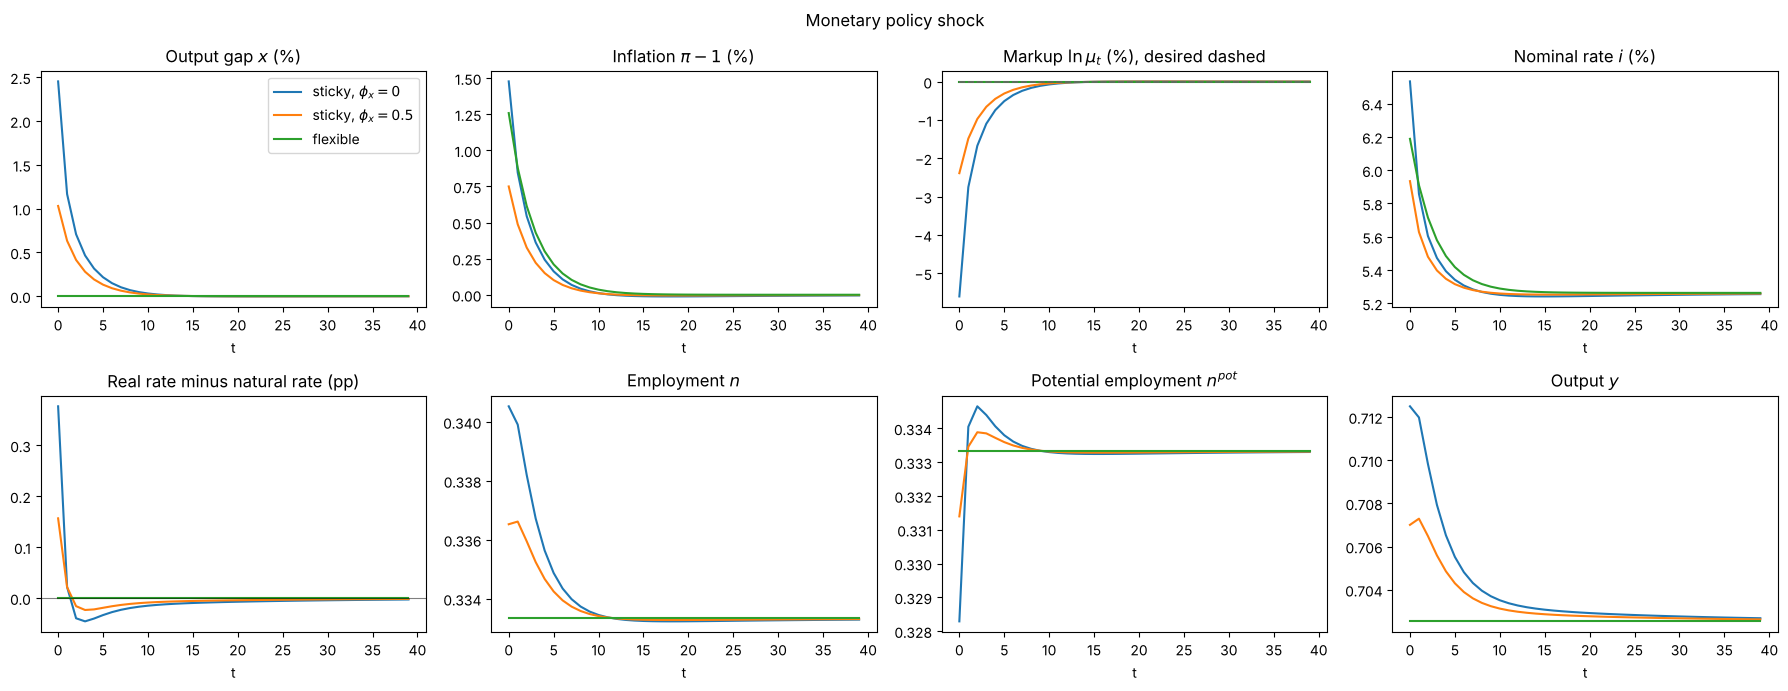

In [15]:
plot_compare([e_m0, e_m1, e_mf], [r'sticky, $\phi_x = 0$', r'sticky, $\phi_x = 0.5$', 'flexible'],
             natural=e_mf, title='Monetary policy shock')

With flexible prices the gap stays at zero: the economy is always at potential, and the shock only moves nominal variables. A monetary shock does not change the natural real rate, so the natural rate here is the no-shock path $r^n_t$.

With sticky prices and $\phi_x = 0$, the gap opens to about 2.5% on impact. Firms' markups are squeezed below the level they want, which is what drives inflation.

The gap is larger than the rise in employment alone would suggest, because potential employment **falls** on impact. Potential holds fixed the firm's marginal labour adjustment cost, and at $t = 0$ firms are hiring fast, so that cost is high. With labour effectively more expensive, the efficient level of employment for today's capital stock is lower. The effect fades after the first period, and potential employment then sits slightly above steady state: the household is working more and enjoying less leisure, so its utility index $u_t$ is below normal, and at a lower $u_t$ it supplies more labour at any given wage.

Responding to the gap ($\phi_x = 0.5$) roughly halves both the output gap and inflation. After a monetary shock the two move together, because both come from the same squeezed markup. A policy that leans against the gap therefore also stabilises inflation, and there is no trade-off.

## Markups and a cost-push shock

It helps to think about pricing in terms of the **markup**, the ratio of price to marginal cost:

$$
\mu_t = \frac{p_t}{p^{bt}_{y,t}} = \frac{1}{mc_t}
$$

This is the markup net of the subsidy, the one that matters for efficiency. Because the subsidy cancels the usual markup $\varepsilon/(\varepsilon - 1)$, firms' **desired** markup in steady state is $\mu^* = 1$, which is the same as $mc = 1$.

A **cost-push shock** $m_t$ raises the desired markup. The firm's gross markup target becomes

$$
M_t = \frac{\varepsilon}{\varepsilon - 1}\, e^{m_t}
$$

which is equivalent to a lower demand elasticity $\varepsilon_t = M_t/(M_t - 1)$: customers become less price-sensitive, and each firm has more pricing power. The subsidy $\tau_s$ is **not** adjusted, so the desired markup net of the subsidy rises to $\mu^*_t = e^{m_t}$, and the real marginal cost firms are aiming for falls to $mc^*_t = e^{-m_t}$.

Rewriting the Phillips curve in terms of markups shows what drives inflation. Since $(1+\tau_s)(\varepsilon_t - 1)/\varepsilon_t = e^{-m_t}$, its first two terms are exactly $\varepsilon_t (mc_t - mc^*_t)$, and linearising around zero inflation gives

$$
\hat\pi_t \approx \frac{\varepsilon}{\zeta_p}\left(\ln \mu^*_t - \ln \mu_t\right) + \beta\, \hat\pi_{t+1}
$$

**Inflation is the result of firms' actual markup falling short of the markup they want**, now or in the future. Raising prices is how they close the shortfall. In Part I, the monetary shock pushed the actual markup down while the desired one stayed at one. A cost-push shock instead raises the desired markup itself.

That also separates two allocations that have coincided until now:

- the **natural** allocation, which the flexible-price economy delivers, has firms at their desired markup, $mc_t = e^{-m_t}$, while
- the **efficient** allocation, against which we measure the output gap, has $mc_t = 1$.

The difference between them is the part of the markup the subsidy no longer offsets. If the government raised the subsidy in step with the shock, the two would stay identical and the shock would have no real effects. Shocks that do not open a wedge between price and marginal cost, such as technology or preference shocks, move the natural and efficient allocations together, so stabilising inflation also closes the gap (the "divine coincidence" of Blanchard and Galí). Shocks to markups, wage markups or distorting taxes break that coincidence.


Now lets raise firms' desired markup by 5 log points, fading at rate $0.7$:

$$
m_t = 0.05 \times 0.7^t
$$

The gross markup target rises from 20% to about 26%, equivalent to the elasticity $\varepsilon_t$ falling from 6 to about 4.8. The shock is half gone after two periods and essentially gone by $t = 10$. Nothing else changes: technology, the capital stock and preferences are as before, so the economy could produce exactly what it produced the period before.

We solve four versions:

- **flexible prices** ($\zeta_p = 0$), which gives the natural allocation,
- **sticky prices with strict inflation targeting**, approximated by $\phi_\pi = 1000$,
- **sticky prices with the inflation-only rule** ($\phi_x = 0$), and
- **sticky prices with the gap rule** ($\phi_x = 0.5$).

In [16]:
m = 0.05 * 0.7 ** t

_, e_cf = run_gap(econ_b_ss, markup=m, zeta_p=0.0, verbose=False, **kw_ss)
_, e_cs = run_gap(econ_b_ss, markup=m, phi_x=0.0, phi_pi=1000.0, verbose=False, **kw_ss)
_, e_c0 = run_gap(econ_b_ss, markup=m, phi_x=0.0, verbose=False, **kw_ss)
_, e_c1 = run_gap(econ_b_ss, markup=m, phi_x=0.5, verbose=False, **kw_ss)

cases = [('flexible (natural)', e_cf), ('sticky, strict targeting', e_cs),
         ('sticky, phi_x = 0', e_c0), ('sticky, phi_x = 0.5', e_c1)]
colors = {'flexible (natural)': 'C2', 'sticky, strict targeting': 'k',
          'sticky, phi_x = 0': 'C0', 'sticky, phi_x = 0.5': 'C1'}
rn_shock = e_cf['r_real']                       # the natural real rate under the shock

print(f'desired markup at t = 0: {100 * m[0]:.2f}%\n')
print(f'{"":26s}{"markup t=0":>12s}{"gap t=0":>10s}{"peak infl.":>12s}{"stance":>10s}')
for name, e in cases:
    stance = 100 * np.sum(e['r_real'] - rn_shock)          # cumulative real-rate gap vs natural, pp
    print(f'{name:26s}{-100 * np.log(e["mc"][0]):11.2f}%{100 * e["gap"][0]:9.2f}%'
          f'{100 * np.max(e["pi"] - 1):11.2f}%{stance:+10.2f}')
print(f'\nstrict targeting vs flexible: max |n diff| = {np.max(np.abs(e_cs["n"] - e_cf["n"])):.1e}')

desired markup at t = 0: 5.00%

                            markup t=0   gap t=0  peak infl.    stance
flexible (natural)               5.00%    -2.11%       1.20%     +0.00
sticky, strict targeting         5.00%    -2.11%       0.00%     +0.00
sticky, phi_x = 0                6.56%    -2.74%       0.12%     +0.19
sticky, phi_x = 0.5              2.88%    -1.22%       0.71%     -0.09

strict targeting vs flexible: max |n diff| = 2.4e-06


"Stance" is the cumulative real-rate gap, $\sum_t (r_t - r^n_t)$, in percentage points, measured against the natural real rate under the shock. Positive means tighter than the natural path. We come back to it below.

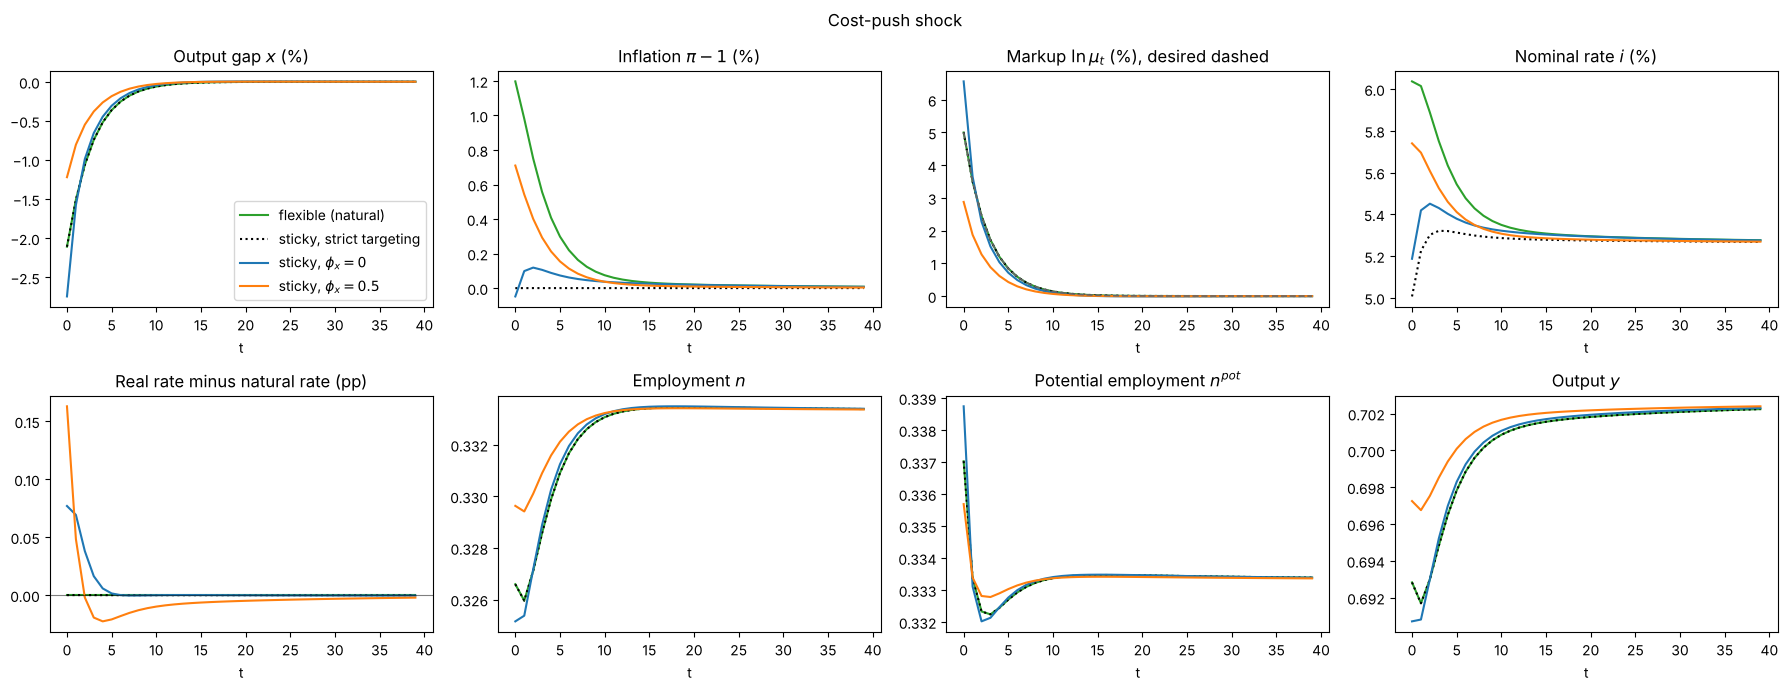

In [17]:
plot_compare([e_cf, e_cs, e_c0, e_c1],
             ['flexible (natural)', 'sticky, strict targeting', r'sticky, $\phi_x = 0$', r'sticky, $\phi_x = 0.5$'],
             natural=e_cf, desired_markup=m, styles=['-', ':', '-', '-'],
             colors=[colors[name] for name, _ in cases], title='Cost-push shock')

### Why marginal cost falls: the natural allocation

Start with flexible prices. Firms reprice freely, so they go straight to their desired markup: the markup rises by 5% and real marginal cost falls to $e^{-0.05} \approx 0.951$.

Real marginal cost is real unit labour cost, $(w_t/p_t + MLAC_t/p_t)\, n_t / ((1-\alpha) Y_t)$. A lower $mc$ means labour and capital are paid less relative to what they produce. With capital fixed in the short run, $mc$ rises with employment: more hours mean a lower marginal product of labour and a higher real wage to get people to work. So the only way real marginal cost can fall is for **employment and output to fall**.

- The real wage falls relative to productivity, so the household works less.
- The return to capital falls, so investment falls.
- Higher profits reach the household as dividends, but they don't depend on how much anyone works or invests, so they don't offset the weaker incentives.

In [18]:
print('flexible prices, t = 0, % deviation from steady state')
for key, lab in [('real_w', 'real wage'), ('n', 'employment'), ('I', 'investment'), ('c', 'consumption'), ('y', 'output')]:
    print(f'  {lab:12s} {100 * (e_cf[key][0] / econ_b_ss[key][0] - 1):6.2f}%')

flexible prices, t = 0, % deviation from steady state
  real wage     -1.72%
  employment    -2.02%
  investment    -7.96%
  consumption   -0.72%
  output        -1.38%


The natural allocation is a recession relative to what the economy could produce, with a gap of about $-2.1\%$ on impact. That is the work of the un-offset markup, not of price stickiness.

Potential employment **rises** on impact, the mirror image of the monetary shock. Firms are cutting staff at $t = 0$, so keeping one more worker saves on the cost of the cut: the marginal labour adjustment cost is negative, and labour is effectively cheaper than the wage. Potential, which holds that wedge fixed, is therefore higher. From $t = 1$ the wedge is small, and potential sits slightly below steady state, because the household is working less and enjoying more leisure, so its utility index is above normal.

The flexible economy also shows 1.2% inflation. That is firms marking up their prices, which costs nothing when prices are flexible. Its exact size is set by the policy rule and has no real consequences.

### With sticky prices, monetary policy chooses how the markup rises

With sticky prices, firms still want the markup to rise by 5%, but marking up prices is now costly. There are two ways the actual markup $1/mc_t$ can rise towards the desired one:

1. **prices rise** gradually, which is inflation, or
2. **costs fall** relative to prices, which happens when demand, employment and real marginal cost fall.

Monetary policy decides the mix, because it controls demand. In the markup panel, inflation appears when a sticky-price economy's markup sits **below** the dashed desired line. The flexible and strict-targeting markups lie on top of that line, since both put firms exactly at their desired markup.

### The natural real rate falls

To judge how tight each rule is, we need the natural real rate under the shock: the real rate path of the flexible economy. It is **not** the pre-shock natural rate $r^n_t$ that the rules are anchored on.

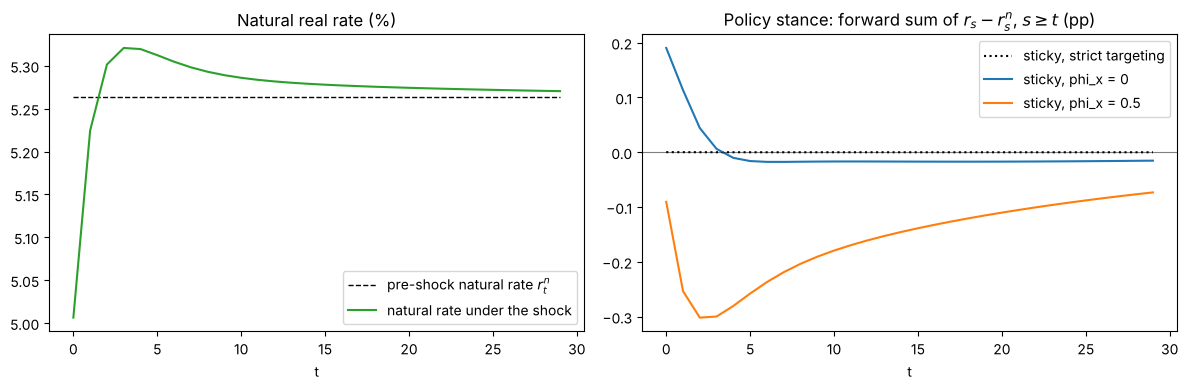

natural real rate minus pre-shock rate, t = 0..2: [-0.257 -0.039  0.038] pp
flexible consumption, t = 0..2: [-0.72 -0.94 -0.89] % from steady state


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
T_show = 30
ax[0].plot(100 * econ_b_ss['r_real'][:T_show], 'k--', lw=1, label='pre-shock natural rate $r^n_t$')
ax[0].plot(100 * rn_shock[:T_show], color='C2', label='natural rate under the shock')
ax[0].set(title='Natural real rate (%)', xlabel='t')
ax[0].legend()

for (name, e), ls in zip(cases[1:], [':', '-', '-']):
    gap_r = 100 * (e['r_real'] - rn_shock)
    forward = np.cumsum(gap_r[::-1])[::-1]               # sum over s >= t of (r_s - r^n_s)
    ax[1].plot(forward[:T_show], ls=ls, color=colors[name], label=name)
ax[1].axhline(0, color='k', lw=0.8, alpha=0.5)
ax[1].set(title='Policy stance: forward sum of $r_s - r^n_s$, $s \\geq t$ (pp)', xlabel='t')
ax[1].legend()
plt.tight_layout()
plt.show()

c_dev = 100 * (e_cf['c'][:3] / econ_b_ss['c'][:3] - 1)
print(f'natural real rate minus pre-shock rate, t = 0..2: {np.round(100 * (rn_shock[:3] - econ_b_ss["r_real"][:3]), 3)} pp')
print(f'flexible consumption, t = 0..2: {np.round(c_dev, 2)} % from steady state')

The natural real rate falls by about a quarter of a percentage point on impact, then rises slightly above normal from $t = 2$. The reason is the household's Euler equation. Consumption keeps falling between $t = 0$ and $t = 1$, so the marginal utility of consumption is expected to rise. With tomorrow's consumption worth more than today's, the real rate has to be below normal to stop households trying to save more than the economy can usefully invest. Once the economy starts recovering, consumption grows, and the real rate has to be above normal.

The right panel measures each rule's **stance**: at each date, the sum of all current and future gaps between the real rate and the natural rate. This forward-looking sum is what matters. Through the Euler equation, today's consumption depends on the whole expected path of real rates, much like a long-term real bond yield. Investment depends on Tobin's $q$, which values the whole expected stream of future returns to capital. A rate that is higher in one period but lower for many periods afterwards can be looser overall.

### How each rule responds

**Strict inflation targeting** keeps inflation at zero, so firms' markups must reach the desired level through lower costs alone. The real rate tracks the natural rate exactly, and the economy reproduces the natural allocation: a gap of $-2.1\%$, no inflation, and a stance of zero. The same allocation would result from the inflation-only rule if it were anchored on the natural rate *under the shock* instead of the pre-shock one.

**The inflation-only rule ($\phi_x = 0$)** is anchored on the pre-shock natural rate. It doesn't see the natural rate fall, so its real rate sits above the natural rate for the first five periods, and within a basis point of it afterwards: a stance of about $+0.19$pp. Demand falls by more than the markup shock requires, real marginal cost falls further than firms want, and their actual markup **overshoots** the desired one. Inflation is close to zero, slightly negative on impact, and the gap reaches $-2.7\%$, deeper than the natural allocation. This rule ends up worse than strict targeting on the gap without any gain on inflation.

**The gap rule ($\phi_x = 0.5$)** sees the negative gap and holds the real rate **below** the natural rate from $t = 2$ onwards, for a stance of about $-0.09$pp. Demand holds up better, employment falls less, and the actual markup stays **below** the desired one. Firms respond by raising prices, and inflation peaks around $0.7\%$. In return, the gap on impact is only $-1.2\%$.

The nominal and real rates at $t = 0$ are nonetheless **higher** under the gap rule than under the inflation-only rule. The rule sets the nominal rate in response to inflation, so the inflation that the looser stance creates feeds straight back into the rate:

In [20]:
for name, e in [('phi_x = 0  ', e_c0), ('phi_x = 0.5', e_c1)]:
    phi_x = 0.5 if '0.5' in name else 0.0
    infl_term = 100 * s_st.phi_pi * np.log(e['pi'][0])
    gap_term = 100 * phi_x * e['gap'][0]
    total = 100 * (np.log(1 + e['i'][0]) - np.log(1 + econ_b_ss['r_real'][0]))
    print(f'{name}: log(1+i_0) - log(1+r^n_0) = {infl_term:+.2f} (inflation) {gap_term:+.2f} (gap) = {total:+.2f} pp')

phi_x = 0  : log(1+i_0) - log(1+r^n_0) = -0.07 (inflation) -0.00 (gap) = -0.07 pp
phi_x = 0.5: log(1+i_0) - log(1+r^n_0) = +1.06 (inflation) -0.61 (gap) = +0.45 pp


Under the gap rule, the inflation response outweighs the cut from the gap term on impact, so the nominal rate rises. Inflation fades faster than the gap, so from $t = 2$ the gap term dominates and keeps real rates below their natural level for a long time. The same pattern appeared after the monetary shock in Part I: **the level of the nominal rate is an outcome of the rule, not a measure of the stance.** High nominal rates often come with loose policy, because loose policy creates the inflation the rule responds to.

### The trade-off

Every sticky-price outcome lies on a line between two points:

- **zero inflation**, achieved by letting firms' markups rise through lower costs, which means accepting the natural recession (gap $-2.1\%$), and
- **a smaller gap**, achieved by holding demand up, which leaves markups below the desired level, so firms raise prices and inflation rises.

No policy reaches zero inflation and a zero gap together, because the shock has raised the markup firms want above the efficient one. The gap rule chooses a point that accepts 0.7% inflation to roughly halve the gap. The inflation-only rule, misled by its anchor, lands below the line: a deeper slump than strict targeting with essentially the same inflation.

Contrast this with the monetary shock. There, inflation and the gap came from the same squeezed markup, so leaning against one also reduced the other. A cost-push shock moves the target markup itself, so inflation and the gap pull in opposite directions. That is why supply-side inflation, such as an energy-price spike or a widening of profit margins, is much harder for central banks than inflation driven by demand.

## Summary

Each step in this lecture added equations to the price system without changing the method:

- Monopolistic competition and a production subsidy replaced marginal-cost pricing with a Phillips curve whose flexible-price limit is the CGE pricing condition.
- A policy rule anchored on the natural rate made the nominal interest rate an unknown and pinned down the price level. Without shocks, the sticky economy reproduces the flexible one exactly.
- Potential employment became one more unknown per period, defined by a static efficiency condition, and the gap entered the policy rule.
- A cost-push shock entered as a time-varying elasticity in the Phillips curve. It raises firms' desired markup above the efficient one, so inflation and the output gap can no longer be stabilised together.
- The policy stance is the expected path of the real rate relative to the natural rate, not the level of the nominal rate, which responds to the inflation that policy itself allows.

The largest system here, the gap model with $T = 100$, has 806 unknowns, solved in a few dozen damped Newton steps from the flexible-price guess. Adding shocks to technology or preferences, a fiscal rule, or several sectors would follow the same pattern: new prices in the price block and new errors in the stacked system.